# Part 4 of 4: Which differences are real? Hypothesis tests, findings and advice

**Input:** `wedmegood_clean.csv` (from Part 2)

Charts show differences. A hypothesis test asks: *is this difference big enough that it is unlikely to be just chance in this sample?*

| Business question | Test used |
|---|---|
| Is the typical rental cost equal to a budget? Is the average rating above a benchmark? | One-sample **z-test** |
| Do two groups (rooms / no rooms, promoted / organic) have different rental cost? | Two-sample **t-test** |
| Do two groups differ in a percentage? | Two-proportion **z-test** |
| Does rental cost differ across 3+ groups (venue type, capacity group)? | One-way **ANOVA**, then **Tukey** to find which pairs differ |
| Are two categories linked? | **Chi-square** test of independence |
| Are two numbers linearly related? | **Pearson correlation** test |

**Rules used**
- Significance level **α = 0.05**. If the p-value is below 0.05 we reject the null hypothesis (H0).
- Rental cost is very skewed, so tests on cost use **log10(rental cost)**. A log difference of 0.30 means about 2 times higher. Results are converted back to "times higher" so they are easy to read.
- Every test also gives an **effect size**, because with enough venues even a tiny difference becomes "significant".
- Many tests are run, so a stricter **Bonferroni** threshold is shown at the end.
- Tests show association in this sample, not cause and effect.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 90

df = pd.read_csv("wedmegood_clean.csv")
if df["rental_cost"].notna().sum() < 10:
    raise SystemExit("STOP: fewer than 10 venues have a rental cost in wedmegood_clean.csv. Re-run Parts 1 and 2 first.")

# Yes/No columns come back from the file as True/False
for col in ["is_paid", "has_rental_cost", "has_rooms", "enough_reviews"]:
    df[col] = df[col].fillna(False).astype(bool)

# Put the grouped columns back in their natural order
ORDER = {
    "rental_tier": ["Low", "Mid", "High"],
    "capacity_group": ["Up to 500", "501-1000", "1001-3000", "Above 3000"],
    "rating_group": ["Below 4.5", "4.5 to 4.9", "5.0"],
    "review_group": ["0", "1", "2 to 4", "5 to 9", "10+"],
}
for col, cats in ORDER.items():
    df[col] = pd.Categorical(df[col].astype(str), categories=cats, ordered=True)


def rs(x):
    """Format a number as rupees, for example 150000 -> ₹150,000"""
    return f"₹{x:,.0f}"


def count_in_order(series, order):
    """Count how many venues are in each group, in the order given (zero if a group is empty)."""
    s = series.astype(object)
    return pd.Series({k: int((s == k).sum()) for k in order})


print(f"Loaded {len(df)} venues and {df.shape[1]} columns.")

Loaded 421 venues and 29 columns.


In [2]:
from scipy import stats

alpha = 0.05
results = []   # every test adds one row here


def save_result(question, test, stat, p, effect_name, effect):
    results.append({"Question": question, "Test": test, "Statistic": round(float(stat), 2), "p_value": float(p),
                    "Effect measure": effect_name, "Effect size": round(float(effect), 2),
                    "Decision": "Reject H0" if p < alpha else "Fail to reject H0"})


def two_group_ttest(a, b, name_a, name_b, question):
    """t-test on log10 rental cost for two groups (Welch version if variances differ)."""
    a, b = a.dropna(), b.dropna()
    if len(a) < 5 or len(b) < 5:
        print(f"Not enough venues for a reliable test ({name_a}: {len(a)}, {name_b}: {len(b)}). Skipped.")
        return
    lev_p = stats.levene(a, b).pvalue
    t, p = stats.ttest_ind(a, b, equal_var=lev_p >= alpha)
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    d = (a.mean() - b.mean()) / pooled if pooled > 0 else 0.0
    print(f"{name_a}: n={len(a)}, typical cost {rs(10 ** a.mean())}  |  {name_b}: n={len(b)}, typical cost {rs(10 ** b.mean())}")
    print(f"{'Welch t-test' if lev_p < alpha else 'Standard t-test'} (Levene p = {lev_p:.3g}): t = {t:.2f}, p = {p:.4g}, Cohen's d = {d:.2f}")
    print(f"{name_a} cost {10 ** (a.mean() - b.mean()):.2f} times {name_b} (on the typical-cost scale).")
    print("Decision:", "Reject H0, the costs differ." if p < alpha else "Fail to reject H0, no clear difference.")
    save_result(question, "Two-sample t-test", t, p, "Cohen's d", d)


def two_prop_ztest(x1, n1, x2, n2, name_1, name_2, question):
    """z-test for two percentages."""
    if n1 == 0 or n2 == 0:
        print("One group is empty. Skipped.")
        return
    if min(x1, n1 - x1, x2, n2 - x2) < 5:
        print("Fewer than 5 venues in one of the four cells, so the z-test is not reliable. Skipped.")
        return
    p1, p2 = x1 / n1, x2 / n2
    pool = (x1 + x2) / (n1 + n2)
    se = np.sqrt(pool * (1 - pool) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    p = 2 * stats.norm.sf(abs(z))
    print(f"{name_1}: {x1}/{n1} = {p1:.1%}  |  {name_2}: {x2}/{n2} = {p2:.1%}")
    print(f"z = {z:.2f}, p = {p:.4g}, difference = {(p1 - p2) * 100:+.1f} percentage points")
    print("Decision:", "Reject H0, the shares differ." if p < alpha else "Fail to reject H0, no clear difference.")
    save_result(question, "Two-proportion z-test", z, p, "Difference (pp)", (p1 - p2) * 100)


def anova_test(groups, question):
    """One-way ANOVA on log10 rental cost. groups = {name: series}. Groups with fewer than 5 venues are left out."""
    groups = {k: v.dropna() for k, v in groups.items()}
    groups = {k: v for k, v in groups.items() if len(v) >= 5}
    if len(groups) < 2:
        print("Fewer than 2 groups have 5 or more priced venues. Skipped.")
        return
    names, samples = list(groups.keys()), list(groups.values())
    f_stat, p = stats.f_oneway(*samples)
    lev_p = stats.levene(*samples).pvalue
    allv = np.concatenate([s.values for s in samples])
    grand = allv.mean()
    eta = sum(len(s) * (s.mean() - grand) ** 2 for s in samples) / ((allv - grand) ** 2).sum()
    print("Typical cost by group: " + ", ".join(f"{n}: {rs(10 ** s.mean())} (n={len(s)})" for n, s in zip(names, samples)))
    print(f"F = {f_stat:.2f}, p = {p:.4g}, eta squared = {eta:.2f} (the groups explain about {eta * 100:.0f}% of the variation in log cost)")
    print(f"Levene p = {lev_p:.3g} ({'variances differ, read with some care' if lev_p < alpha else 'variances are similar'})")
    print("Decision:", "Reject H0, at least one group differs." if p < alpha else "Fail to reject H0, no clear difference.")
    if lev_p < alpha:
        p_kw = stats.kruskal(*samples).pvalue
        print(f"Robustness check (Kruskal-Wallis): p = {p_kw:.4g} -> {'same conclusion' if (p_kw < alpha) == (p < alpha) else 'different conclusion, be careful'}")
    if p < alpha:
        try:
            tukey = stats.tukey_hsd(*samples)
            print("Pairs that differ (Tukey HSD, p < 0.05):")
            found = 0
            for i in range(len(names)):
                for j in range(i + 1, len(names)):
                    if tukey.pvalue[i, j] < alpha:
                        diff = samples[i].mean() - samples[j].mean()
                        dearer, cheaper = (names[i], names[j]) if diff >= 0 else (names[j], names[i])
                        pv = tukey.pvalue[i, j]
                        ptxt = f"p = {pv:.3g}" if pv >= 0.001 else "p < 0.001"
                        print(f"  - {dearer} costs {10 ** abs(diff):.2f} times {cheaper} ({ptxt})")
                        found += 1
            if found == 0:
                print("  None stands out after the Tukey correction.")
        except Exception as err:
            print("Tukey follow-up was not possible here:", type(err).__name__)
    save_result(question, "One-way ANOVA", f_stat, p, "Eta squared", eta)


def chi_square_test(table, question):
    """Chi-square test of independence for a table of counts."""
    table = table.loc[table.sum(axis=1) > 0, table.sum(axis=0) > 0]
    if table.shape[0] < 2 or table.shape[1] < 2:
        print("The table has fewer than 2 rows or columns with venues. Skipped.")
        return
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    print(table.to_string())
    print(f"chi2 = {chi2:.2f}, dof = {dof}, p = {p:.4g}, Cramer's V = {v:.2f}")
    print(f"Cells with expected count below 5: {int((expected < 5).sum())} of {expected.size} (few is better)")
    print("Decision:", "Reject H0, the two are linked." if p < alpha else "Fail to reject H0, no clear link.")
    save_result(question, "Chi-square independence", chi2, p, "Cramer's V", v)


print("Test helpers are ready. Skewness check:")
lc = df["log_rental_cost"].dropna()
print(f"  skewness of raw rental cost = {df['rental_cost'].skew():.2f}, of log10 rental cost = {lc.skew():.2f} (closer to 0 is more bell-shaped)")

Test helpers are ready. Skewness check:
  skewness of raw rental cost = 5.79, of log10 rental cost = 0.27 (closer to 0 is more bell-shaped)


## 1. Is the typical rental cost equal to a family's budget? (one-sample z-test)
**Business question:** A family plans to spend ₹1,00,000 on the venue. Is that the typical rental cost?  
**H0:** the typical (geometric mean) rental cost = the budget. **H1:** it is different.  
Change `BUDGET` to test another amount.

In [3]:
BUDGET = 100000
lc = df["log_rental_cost"].dropna()
if len(lc) >= 30:
    se = lc.std(ddof=1) / np.sqrt(len(lc))
    z = (lc.mean() - np.log10(BUDGET)) / se
    p = 2 * stats.norm.sf(abs(z))
    d = (lc.mean() - np.log10(BUDGET)) / lc.std(ddof=1)
    print(f"n = {len(lc)}, typical (geometric mean) rental cost = {rs(10 ** lc.mean())}, budget = {rs(BUDGET)}")
    print(f"z = {z:.2f}, p = {p:.4g}, Cohen's d = {d:.2f}")
    print("Decision:", f"Reject H0. The typical cost is {'above' if z > 0 else 'below'} the budget." if p < alpha else "Fail to reject H0. The budget is in line with the typical cost.")
    save_result(f"Typical rental cost vs {rs(BUDGET)}", "One-sample z-test", z, p, "Cohen's d", d)
else:
    print("Fewer than 30 priced venues, so the z-test is skipped.")

n = 119, typical (geometric mean) rental cost = ₹104,191, budget = ₹100,000
z = 0.37, p = 0.7084, Cohen's d = 0.03
Decision: Fail to reject H0. The budget is in line with the typical cost.


## 2. Is the average rating really above 4.5? (one-sample z-test)
**H0:** the mean rating = 4.5. **H1:** it is different.

In [4]:
ratings = df["rating"].dropna()
if len(ratings) >= 30 and ratings.std(ddof=1) > 0:
    mu0 = 4.5
    z = (ratings.mean() - mu0) / (ratings.std(ddof=1) / np.sqrt(len(ratings)))
    p = 2 * stats.norm.sf(abs(z))
    d = (ratings.mean() - mu0) / ratings.std(ddof=1)
    print(f"n = {len(ratings)}, mean rating = {ratings.mean():.2f}, benchmark = {mu0}")
    print(f"z = {z:.2f}, p = {p:.4g}, Cohen's d = {d:.2f}")
    print("Decision:", f"Reject H0. The mean rating is {'above' if z > 0 else 'below'} {mu0}." if p < alpha else f"Fail to reject H0. No clear difference from {mu0}.")
    save_result("Mean rating vs 4.5", "One-sample z-test", z, p, "Cohen's d", d)
else:
    print("Not enough rated venues (or no spread in ratings), so the z-test is skipped.")

n = 297, mean rating = 4.76, benchmark = 4.5
z = 9.07, p = 1.24e-19, Cohen's d = 0.53
Decision: Reject H0. The mean rating is above 4.5.


## 3. Do venues with rooms have a different rental cost? (two-sample t-test)
**H0:** mean log10 rental cost is the same with and without rooms. **H1:** it is different.

In [5]:
two_group_ttest(df.loc[df["has_rooms"], "log_rental_cost"], df.loc[~df["has_rooms"], "log_rental_cost"],
                "Rooms shown", "No rooms shown", "Rooms vs no rooms (rental cost)")

Rooms shown: n=71, typical cost ₹124,690  |  No rooms shown: n=48, typical cost ₹79,883
Standard t-test (Levene p = 0.102): t = 2.02, p = 0.04612, Cohen's d = 0.38
Rooms shown cost 1.56 times No rooms shown (on the typical-cost scale).
Decision: Reject H0, the costs differ.


## 4. Do promoted venues have a different rental cost? (two-sample t-test)
**H0:** mean log10 rental cost is the same for promoted and organic listings. **H1:** it is different.

In [6]:
two_group_ttest(df.loc[df["is_paid"], "log_rental_cost"], df.loc[~df["is_paid"], "log_rental_cost"],
                "Promoted", "Organic", "Promoted vs organic (rental cost)")

Not enough venues for a reliable test (Promoted: 0, Organic: 119). Skipped.


## 5. Do promoted venues show a rental cost as often as organic ones? (two-proportion z-test)
**H0:** the share of venues showing a rental cost is the same in both groups. **H1:** the shares differ.

In [7]:
paid, organic = df[df["is_paid"]], df[~df["is_paid"]]
two_prop_ztest(int(paid["has_rental_cost"].sum()), len(paid), int(organic["has_rental_cost"].sum()), len(organic),
               "Promoted", "Organic", "Promoted vs organic (share showing rental cost)")

One group is empty. Skipped.


## 6. Is a perfect 5.0 more common when there are few reviews? (two-proportion z-test)
**H0:** the share of 5.0 ratings is the same for venues with fewer than 5 reviews and with 5 or more. **H1:** it is different.

In [8]:
rated = df[df["rating"].notna()]
few, many = rated[~rated["enough_reviews"]], rated[rated["enough_reviews"]]
two_prop_ztest(int((few["rating"] == 5.0).sum()), len(few), int((many["rating"] == 5.0).sum()), len(many),
               "Fewer than 5 reviews", "5+ reviews", "5.0 ratings: few vs many reviews")

Fewer than 5 reviews: 179/242 = 74.0%  |  5+ reviews: 20/55 = 36.4%
z = 5.35, p = 8.618e-08, difference = +37.6 percentage points
Decision: Reject H0, the shares differ.


## 7. Does rental cost differ between venue types? (one-way ANOVA + Tukey)
**H0:** all venue types have the same mean log10 rental cost. **H1:** at least one type differs.  
Effect size: eta squared (about 0.01 small, 0.06 medium, 0.14 large).

In [9]:
type_groups = {t: g["log_rental_cost"] for t, g in df.groupby("venue_group")}
anova_test(type_groups, "Rental cost across venue types")

Typical cost by group: Banquet & Lawn: ₹143,213 (n=22), Banquet Hall: ₹58,101 (n=23), Convention Hall: ₹256,661 (n=27), Farmhouse: ₹64,402 (n=14), Lawn: ₹68,995 (n=21)
F = 9.53, p = 1.37e-06, eta squared = 0.27 (the groups explain about 27% of the variation in log cost)
Levene p = 0.0553 (variances are similar)
Decision: Reject H0, at least one group differs.
Pairs that differ (Tukey HSD, p < 0.05):
  - Banquet & Lawn costs 2.46 times Banquet Hall (p = 0.0274)
  - Convention Hall costs 4.42 times Banquet Hall (p < 0.001)
  - Convention Hall costs 3.99 times Farmhouse (p < 0.001)
  - Convention Hall costs 3.72 times Lawn (p < 0.001)


## 8. Does rental cost differ between capacity groups? (one-way ANOVA + Tukey)

In [10]:
cap_groups = {str(c): df.loc[df["capacity_group"] == c, "log_rental_cost"] for c in ORDER["capacity_group"]}
anova_test(cap_groups, "Rental cost across capacity groups")

Typical cost by group: Up to 500: ₹48,184 (n=44), 501-1000: ₹86,840 (n=35), 1001-3000: ₹288,667 (n=29), Above 3000: ₹214,954 (n=10)
F = 25.26, p = 1.322e-12, eta squared = 0.40 (the groups explain about 40% of the variation in log cost)
Levene p = 0.152 (variances are similar)
Decision: Reject H0, at least one group differs.
Pairs that differ (Tukey HSD, p < 0.05):
  - 501-1000 costs 1.80 times Up to 500 (p = 0.0255)
  - 1001-3000 costs 5.99 times Up to 500 (p < 0.001)
  - Above 3000 costs 4.46 times Up to 500 (p < 0.001)
  - 1001-3000 costs 3.32 times 501-1000 (p < 0.001)
  - Above 3000 costs 2.48 times 501-1000 (p = 0.0317)


## 9. Is showing a rental cost linked to venue type? (chi-square)
**H0:** whether a venue shows a rental cost is independent of its type. **H1:** it depends on the type.  
Effect size: Cramer's V (about 0.1 small, 0.3 medium, 0.5 large). Types with at least 15 venues are used.

In [11]:
big_types = df["venue_group"].value_counts()[lambda s: s >= 15].index
sub = df[df["venue_group"].isin(big_types)]
chi_square_test(pd.crosstab(sub["venue_group"], sub["has_rental_cost"]), "Venue type vs showing a rental cost")

has_rental_cost  False  True 
venue_group                  
Banquet & Lawn      37     22
Banquet Hall       107     23
Convention Hall     48     27
Farmhouse           11     14
Hotel               46      4
Lawn                23     21
Other               16      4
Resort              14      4
chi2 = 40.58, dof = 7, p = 9.757e-07, Cramer's V = 0.31
Cells with expected count below 5: 0 of 16 (few is better)
Decision: Reject H0, the two are linked.


## 10. Are rental tier and capacity group linked? (chi-square)
**H0:** rental tier is independent of capacity group. **H1:** they are linked (bigger venues sit in different tiers).

In [12]:
tab = pd.crosstab(df["rental_tier"], df["capacity_group"])
chi_square_test(tab.astype(int), "Rental tier vs capacity group")

capacity_group  Up to 500  501-1000  1001-3000  Above 3000
rental_tier                                               
Low                    26        12          1           1
Mid                    16        14          7           2
High                    2         9         21           7
chi2 = 48.84, dof = 6, p = 8.027e-09, Cramer's V = 0.45
Cells with expected count below 5: 3 of 12 (few is better)
Decision: Reject H0, the two are linked.


## 11. Which numbers are linearly related to rental cost? (Pearson correlation test)
**H0:** the linear correlation is 0. **H1:** it is not 0. Skewed columns are on the log scale. Effect size: r squared (share of variation explained).

In [13]:
for label, x_col, y_col in [("Capacity vs rental cost (both log10)", "log_capacity", "log_rental_cost"),
                            ("Rating vs rental cost (log10)", "rating", "log_rental_cost"),
                            ("Extra features vs rental cost (log10)", "extra_features", "log_rental_cost")]:
    pair = df[[x_col, y_col]].dropna()
    if len(pair) < 10 or pair[x_col].nunique() < 2 or pair[y_col].nunique() < 2:
        print(f"{label}: not enough data, skipped.")
        continue
    r, p = stats.pearsonr(pair[x_col], pair[y_col])
    strength = "strong" if abs(r) >= 0.6 else "moderate" if abs(r) >= 0.3 else "weak"
    print(f"{label}: n = {len(pair)}, r = {r:.2f}, r squared = {r ** 2:.2f}, p = {p:.4g} -> {'Reject H0' if p < alpha else 'Fail to reject H0'} ({strength}, {'positive' if r > 0 else 'negative'})")
    save_result(label, "Pearson correlation", r, p, "r squared", r ** 2)

Capacity vs rental cost (both log10): n = 118, r = 0.59, r squared = 0.35, p = 1.467e-12 -> Reject H0 (moderate, positive)
Rating vs rental cost (log10): n = 88, r = -0.14, r squared = 0.02, p = 0.209 -> Fail to reject H0 (weak, negative)
Extra features vs rental cost (log10): n = 119, r = 0.15, r squared = 0.02, p = 0.1054 -> Fail to reject H0 (weak, positive)


## 12. Summary of all tests

11 tests. Bonferroni threshold: 0.0045

                             Question                    Test  Statistic      p_value  Effect measure  Effect size          Decision  Significant at 0.05  Significant after Bonferroni
      Typical rental cost vs ₹100,000       One-sample z-test       0.37 7.080000e-01       Cohen's d         0.03 Fail to reject H0                False                         False
                   Mean rating vs 4.5       One-sample z-test       9.07 1.240000e-19       Cohen's d         0.53         Reject H0                 True                          True
      Rooms vs no rooms (rental cost)       Two-sample t-test       2.02 4.610000e-02       Cohen's d         0.38         Reject H0                 True                         False
     5.0 ratings: few vs many reviews   Two-proportion z-test       5.35 8.620000e-08 Difference (pp)        37.60         Reject H0                 True                          True
       Rental cost across venue types   

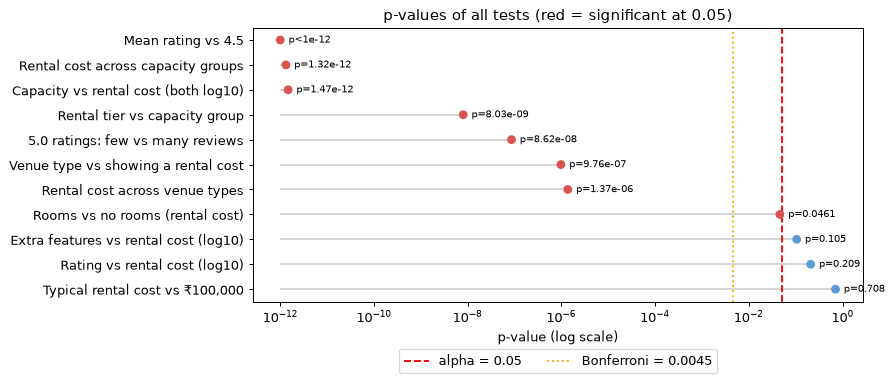

8 of 11 tests are significant at 0.05; 7 stay significant after the Bonferroni correction.
A significant result means the difference is unlikely to be chance. The effect size says whether it is big enough to matter.


In [14]:
summary = pd.DataFrame(results)
if len(summary) == 0:
    print("No test could be run with this data.")
else:
    bonferroni = alpha / len(summary)
    summary["Significant at 0.05"] = summary["p_value"] < alpha
    summary["Significant after Bonferroni"] = summary["p_value"] < bonferroni
    summary["p_value"] = summary["p_value"].map(lambda v: float(f"{v:.3g}"))
    print(f"{len(summary)} tests. Bonferroni threshold: {bonferroni:.4f}\n")
    print(summary.to_string(index=False))

    plot_p = summary.sort_values("p_value", ascending=False)
    floor = 1e-12
    pv = np.maximum(plot_p["p_value"].values.astype(float), floor)
    y = np.arange(len(plot_p))
    plt.figure(figsize=(10, max(3.5, len(plot_p) * 0.4)))
    plt.hlines(y, floor, pv, color="lightgrey")
    plt.scatter(pv, y, color=np.where(pv < alpha, "#d9534f", "#5b9bd5"), zorder=3)
    for yy, v, real in zip(y, pv, plot_p["p_value"].values.astype(float)):
        plt.text(v * 1.5, yy, f"p<{floor:g}" if real < floor else f"p={real:.3g}", va="center", fontsize=8)
    plt.axvline(alpha, color="red", linestyle="--", label=f"alpha = {alpha}")
    plt.axvline(bonferroni, color="orange", linestyle=":", label=f"Bonferroni = {bonferroni:.4f}")
    plt.xscale("log")
    plt.yticks(y, plot_p["Question"].values)
    plt.title("p-values of all tests (red = significant at 0.05)")
    plt.xlabel("p-value (log scale)")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
    plt.tight_layout()
    plt.show()

    sig = summary[summary["Significant at 0.05"]]
    print(f"{len(sig)} of {len(summary)} tests are significant at 0.05; {int(summary['Significant after Bonferroni'].sum())} stay significant after the Bonferroni correction.")
    print("A significant result means the difference is unlikely to be chance. The effect size says whether it is big enough to matter.")

# Key findings
Written by the code from the data above, so every number is real.

In [15]:
cost = df["rental_cost"].dropna()
plate = df["veg_price"].dropna()
vt = df["venue_group"].value_counts()
cap_pair = df[["capacity_max", "rental_cost"]].dropna()
rate_pair = df[["rating", "rental_cost"]].dropna()
rho_cap = cap_pair.corr(method="spearman").iloc[0, 1] if len(cap_pair) > 5 else float("nan")
rho_rate = rate_pair.corr(method="spearman").iloc[0, 1] if len(rate_pair) > 5 else float("nan")
med_rooms = df.loc[df["has_rooms"], "rental_cost"].median()
med_no_rooms = df.loc[~df["has_rooms"], "rental_cost"].median()
rated = df["rating"].dropna()
tc = df.groupby("venue_group").agg(priced=("rental_cost", "count"), med=("rental_cost", "median"))
tc = tc[tc["priced"] >= 5].sort_values("med", ascending=False)

print(f"1. Supply: {len(df)} venues. '{vt.index[0]}' ({vt.iloc[0] / len(df):.0%}) is the biggest type. {df['area'].nunique()} areas appear, and {df['area'].isna().mean():.0%} of listings show no area.")
print(f"2. Rental cost: {len(cost)} venues ({len(cost) / len(df):.0%}) show one. Median {rs(cost.median())}, middle half {rs(cost.quantile(0.25))} to {rs(cost.quantile(0.75))}, dearest {rs(cost.max())}.")
print(f"3. Plate price: {len(plate)} venues show a veg price (median {rs(plate.median()) if len(plate) else 'n/a'}); {int((df['pricing_type'] == 'Both').sum())} venues show both price styles.")
if len(tc) >= 2:
    print(f"4. Venue type: '{tc.index[0]}' has the highest median rental cost ({rs(tc['med'].iloc[0])}) and '{tc.index[-1]}' the lowest ({rs(tc['med'].iloc[-1])}).")
print(f"5. Size and rooms: capacity vs rental cost Spearman {rho_cap:.2f}. Median cost {rs(med_rooms) if pd.notna(med_rooms) else 'n/a'} with rooms vs {rs(med_no_rooms) if pd.notna(med_no_rooms) else 'n/a'} without.")
if len(rated) > 0:
    print(f"6. Ratings: {(rated == 5.0).mean():.0%} of rated venues have a 5.0, {(df['reviews'] < 5).mean():.0%} of all venues have fewer than 5 reviews, and rating vs rental cost Spearman is {rho_rate:.2f}.")
if len(results) > 0:
    names = ", ".join(summary.loc[summary["Significant at 0.05"], "Question"]) or "none"
    print(f"7. Tests: {int(summary['Significant at 0.05'].sum())} of {len(summary)} are significant at 0.05 ({names}).")

1. Supply: 421 venues. 'Banquet Hall' (31%) is the biggest type. 74 areas appear, and 34% of listings show no area.
2. Rental cost: 119 venues (28%) show one. Median ₹94,000, middle half ₹45,000 to ₹260,000, dearest ₹3,500,000.
3. Plate price: 273 venues show a veg price (median ₹500); 42 venues show both price styles.
4. Venue type: 'Convention Hall' has the highest median rental cost (₹350,000) and 'Farmhouse' the lowest (₹60,000).
5. Size and rooms: capacity vs rental cost Spearman 0.64. Median cost ₹100,000 with rooms vs ₹55,000 without.
6. Ratings: 67% of rated venues have a 5.0, 87% of all venues have fewer than 5 reviews, and rating vs rental cost Spearman is -0.23.
7. Tests: 8 of 11 are significant at 0.05 (Mean rating vs 4.5, Rooms vs no rooms (rental cost), 5.0 ratings: few vs many reviews, Rental cost across venue types, Rental cost across capacity groups, Venue type vs showing a rental cost, Rental tier vs capacity group, Capacity vs rental cost (both log10)).


# Business recommendations
The lines below are chosen by the code from the test results, so they only say what the data supports.

In [16]:
def is_sig(question):
    row = summary[summary["Question"] == question] if len(results) > 0 else []
    return bool(len(row) > 0 and row["p_value"].iloc[0] < alpha)

def was_run(question):
    return len(results) > 0 and (summary["Question"] == question).any()

print("CUSTOMERS")
print("- Treat the rental cost as the main price, and add food, decor and other services on top before comparing venues.")
if is_sig("Rental cost across venue types"):
    print("- Venue type clearly changes the rental cost (ANOVA is significant). Compare a venue only with others of the same type.")
else:
    print("- Venue type does not show a clear effect on rental cost in this sample, so compare on size and facilities instead.")
if is_sig("Rental cost across capacity groups") or is_sig("Capacity vs rental cost (both log10)"):
    print("- Size matters for price. Choose the smallest venue that fits your guest list.")
if is_sig("5.0 ratings: few vs many reviews"):
    print("- A 5.0 from only a few reviews is more common than a 5.0 from many. Always read the review count with the rating.")
else:
    print("- Read the review count together with the rating. A rating from very few reviews is weak evidence.")
print("- For venues that show only a plate price, ask for the rental cost and any minimum guest guarantee.")

print("\nVENUE OWNERS")
print("- Check your rental cost against the median for your venue type and capacity group (Part 3, question 13) before changing it.")
if is_sig("Rooms vs no rooms (rental cost)"):
    print("- Rooms are linked to a different rental cost. Make rooms clearly visible on your listing.")
else:
    print("- Showing rooms alone does not show a clear price difference here, so do not rely on rooms alone to justify a higher price.")
if was_run("Rating vs rental cost (log10)") and not is_sig("Rating vs rental cost (log10)"):
    print("- Rating alone does not explain price in this sample. Collect more reviews so your rating is believable.")
print("- Show both a rental cost and a plate price, plus area, rooms and extra features, so customers can compare you easily.")

print("\nMARKETPLACE (WedMeGood)")
print("- Show 'per function' and 'per plate' prices clearly with a filter for each, and ask venues to show both.")
print("- Show the review count next to the rating, or rank by rating and review count together.")
if is_sig("Promoted vs organic (rental cost)") or is_sig("Promoted vs organic (share showing rental cost)"):
    print("- Promoted venues differ from organic ones. Check that promoted slots do not push customers toward one price level without them knowing.")
else:
    print("- No clear price difference between promoted and organic venues in this sample. Keep checking as listings change.")
print("- Use the thin venue types and thin price-and-size segments (Part 3, question 15) when deciding where to add new venues.")

CUSTOMERS
- Treat the rental cost as the main price, and add food, decor and other services on top before comparing venues.
- Venue type clearly changes the rental cost (ANOVA is significant). Compare a venue only with others of the same type.
- Size matters for price. Choose the smallest venue that fits your guest list.
- A 5.0 from only a few reviews is more common than a 5.0 from many. Always read the review count with the rating.
- For venues that show only a plate price, ask for the rental cost and any minimum guest guarantee.

VENUE OWNERS
- Check your rental cost against the median for your venue type and capacity group (Part 3, question 13) before changing it.
- Rooms are linked to a different rental cost. Make rooms clearly visible on your listing.
- Rating alone does not explain price in this sample. Collect more reviews so your rating is believable.
- Show both a rental cost and a plate price, plus area, rooms and extra features, so customers can compare you easily.

MARKETP

# Limitations
- The data is a snapshot of the listings on the day of scraping. Prices and ratings change.
- Only the first listing pages were collected (promoted venues come first), so the sample may lean toward promoted listings and may not cover every venue.
- Not every venue shows a rental cost, an area or rooms. Price and location results come from the venues that do.
- Rental cost per function is a headline number. It leaves out food, decor and other services, so the total cost of a wedding is not in the data.
- Ratings and review counts are low for many venues and may not reflect real customer experience.
- Venue types, price tiers and capacity groups are my own groupings, and some groups are small.
- Hypothesis tests show association in this sample, not cause and effect. Several tests were run, so the Bonferroni check is shown. A non-significant result means no clear evidence in this sample, not proof of no difference.
- If the website changes its layout, the scraping rules in Part 1 need updating.